# Network Analysis & Metriche

**Input:**
- `ultimate_owners_clean.csv` — ownership chains post noise filter
- `owner_conflict_matrix.csv` — matrix owner × conflict
- `ownership_edges.csv` — complete graph with intermediate nodes
- `ownership_nodes.csv` — label and P31 of all nodes

**Output:**
- Bipartite Graph Conflict–Owner (projected)
- Centrality: degree, betweenness, PageRank
- Community detection (Louvain)
- HHI per conflict
- Visualizations: heatmap, network, bar chart HHI

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from pathlib import Path
from IPython.display import display
import matplotlib.patches as mpatches
from collections import defaultdict


try:
    import community as community_louvain
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'python-louvain', '-q'])
    import community as community_louvain

Path('figures').mkdir(exist_ok=True)

# Input files
ult       = pd.read_csv('ultimate_owners_clean.csv')
matrix_df = pd.read_csv('owner_conflict_matrix.csv', index_col=0)
edges_df  = pd.read_csv('ownership_edges.csv')
nodes_df  = pd.read_csv('ownership_nodes.csv')

label_by = nodes_df.groupby('entity')['entityLabel'].first().to_dict()
def lab(x):
    if pd.isna(x): return ''
    s = str(x)
    return label_by.get(s, s.rsplit('/',1)[-1] if '/' in s else s)

print('Files:')
print(f'  ultimate_owners_clean: {len(ult)} righe')
print(f'  owner_conflict_matrix: {matrix_df.shape}')
print(f'  ownership_edges:       {len(edges_df)} righe')
print(f'  ownership_nodes:       {len(nodes_df)} righe')
print(f'\nConflicts: {list(matrix_df.columns)}')


Files:
  ultimate_owners_clean: 605 righe
  owner_conflict_matrix: (61, 9)
  ownership_edges:       822 righe
  ownership_nodes:       1088 righe

Conflicts: ['afghanistan', 'gaza', 'iran_iraq', 'iraq', 'kosovo_1999', 'lebanon_2006', 'nagorno_karabakh', 'syria', 'ukraine']


In [2]:
# Bipartite Graph Conflict–Owner 
# Nodes: conflicts + ultimate owners
# Edges: owner → conflict (weight = n. manufacturer controlled in that conflict)
# controlish mode is used

ctrl = ult[ult['mode'] == 'controlish'].copy()
ctrl = ctrl[ctrl['manufacturer'] != ctrl['ultimateOwner']].copy()

ctrl['conflict_list'] = ctrl['conflict'].str.split('|')
ctrl_exp = ctrl.explode('conflict_list').rename(columns={'conflict_list': 'conflict_single'})


B = nx.Graph()

conflicts = sorted(ctrl_exp['conflict_single'].dropna().unique())
owners    = sorted(ctrl_exp['ultimateOwnerLabel'].dropna().unique())


B.add_nodes_from(conflicts, bipartite='conflict')
B.add_nodes_from(owners,    bipartite='owner')


edge_weights = (
    ctrl_exp.groupby(['ultimateOwnerLabel','conflict_single'])['manufacturer']
    .nunique()
    .reset_index()
    .rename(columns={'manufacturer': 'weight'})
)
for _, r in edge_weights.iterrows():
    B.add_edge(r['ultimateOwnerLabel'], r['conflict_single'], weight=r['weight'])

print(f'Bipartite Graph:')
print(f'  Conflict Nodes: {len(conflicts)}')
print(f'  Owner Nodes:     {len(owners)}')
print(f'  Edges:          {B.number_of_edges()}')

# owner-owner projection (two owner are connected if they share one conflict)
owner_nodes = {n for n, d in B.nodes(data=True) if d.get('bipartite') == 'owner'}
G_owner = nx.bipartite.weighted_projected_graph(B, owner_nodes)

# conflict-conflict projection
conflict_nodes = {n for n, d in B.nodes(data=True) if d.get('bipartite') == 'conflict'}
G_conflict = nx.bipartite.weighted_projected_graph(B, conflict_nodes)

print(f'\nOwner-owner Projection: {G_owner.number_of_nodes()} nodes, {G_owner.number_of_edges()} edges')
print(f'Conflict-conflict Projection: {G_conflict.number_of_nodes()} nodes, {G_conflict.number_of_edges()} edges')

# Complete graph with intermediate nodes
G_full = nx.DiGraph()
for _, r in edges_df.dropna(subset=['manufacturer','owner']).iterrows():
    if r.get('rel','') == 'P361_part_of':
        continue
    G_full.add_edge(r['manufacturer'], r['owner'], rel=r.get('rel',''), weight=1)

print(f'\nComplete Graph:')
print(f'  Nodes: {G_full.number_of_nodes()}')
print(f'  Edges: {G_full.number_of_edges()}')


Bipartite Graph:
  Conflict Nodes: 9
  Owner Nodes:     74
  Edges:          216

Owner-owner Projection: 74 nodes, 1932 edges
Conflict-conflict Projection: 9 nodes, 32 edges

Complete Graph:
  Nodes: 434
  Edges: 524


In [3]:
# Centrality Measures

degree_b = dict(B.degree(weight='weight'))

sample_nodes = list(G_full.nodes())[:3]
print(f'Nodes Example G_full: {sample_nodes}')

# PageRank on complete graph
pagerank    = nx.pagerank(G_full, alpha=0.85, weight='weight')
betweenness = nx.betweenness_centrality(G_full, normalized=True, weight='weight')
in_degree   = dict(G_full.in_degree())


label_to_uri = {}
for _, row in ult.drop_duplicates(subset='ultimateOwner').iterrows():
    uri = str(row['ultimateOwner'])
    lbl = str(row.get('ultimateOwnerLabel',''))
    if uri in G_full.nodes() or uri in pagerank:
        label_to_uri[lbl] = uri

def get_uri_for_owner(label, ult_df):
    match = ult_df[ult_df['ultimateOwnerLabel'] == label]
    if len(match) == 0: return ''
    uri = str(match['ultimateOwner'].iloc[0])
    if uri in pagerank: return uri
    for node in G_full.nodes():
        if uri.rsplit('/',1)[-1] == str(node).rsplit('/',1)[-1]:
            return node
    return uri

centrality_rows = []
for owner in owners:
    uri     = get_uri_for_owner(owner, ult)
    match   = ult[ult['ultimateOwnerLabel'] == owner]
    country = match['ultimateOwnerCountry'].iloc[0] if len(match) > 0 else ''
    n_conflicts = len([c for c in conflicts if B.has_edge(owner, c)])
    centrality_rows.append({
        'owner':       owner,
        'country':     country,
        'n_conflicts': n_conflicts,
        'degree_w':    degree_b.get(owner, 0),
        'pagerank':    pagerank.get(uri, 0.0),
        'betweenness': betweenness.get(uri, 0.0),
        'in_degree':   in_degree.get(uri, 0),
        'uri':         uri,
    })

centrality_df = pd.DataFrame(centrality_rows).sort_values('n_conflicts', ascending=False)
centrality_df.to_csv('owner_centrality.csv', index=False)

nonzero_bw = (centrality_df['betweenness'] > 0).sum()
print(f'Owners with betweenness > 0: {nonzero_bw}/{len(centrality_df)}')

TABLE_STYLES = [
    {'selector': 'th',      'props': [('background-color', '#1e293b'), ('color', 'white'),
                                       ('font-size', '11px'), ('padding', '8px 12px'),
                                       ('text-align', 'left'), ('font-weight', 'bold')]},
    {'selector': 'td',      'props': [('font-size', '11px'), ('padding', '6px 12px'),
                                       ('border-bottom', '1px solid #e2e8f0')]},
    {'selector': 'table',   'props': [('border-collapse', 'collapse'), ('margin', '12px 0')]},
    {'selector': 'tr:hover td', 'props': [('background-color', '#f1f5f9')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '12px'),
                                       ('font-weight', 'bold'), ('color', '#1e293b'),
                                       ('padding', '8px 0'), ('text-align', 'left')]},
]

# Top 20 per n_conflicts
top20 = centrality_df.head(20)[['owner','country','n_conflicts','degree_w','pagerank','betweenness','in_degree']].copy()
display(
    top20.style
    .background_gradient(subset=['n_conflicts','degree_w'], cmap='Blues')
    .background_gradient(subset=['pagerank'], cmap='Oranges')
    .background_gradient(subset=['betweenness'], cmap='Purples')
    .format({'pagerank': '{:.4f}', 'betweenness': '{:.4f}'})
    .set_caption('Top 20 owners by number of conflicts (controlish mode)')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)

# Top 10 per betweenness
top_bw = centrality_df.nlargest(10, 'betweenness')[['owner','country','betweenness','n_conflicts']].copy()
display(
    top_bw.style
    .background_gradient(subset=['betweenness'], cmap='Purples')
    .background_gradient(subset=['n_conflicts'], cmap='Blues')
    .format({'betweenness': '{:.5f}'})
    .set_caption('Top 10 owners by betweenness centrality (bridge nodes in ownership graph)')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)

# Top 10 per pagerank
top_pr = centrality_df.nlargest(10, 'pagerank')[['owner','country','pagerank','n_conflicts']].copy()
display(
    top_pr.style
    .background_gradient(subset=['pagerank'], cmap='Oranges')
    .background_gradient(subset=['n_conflicts'], cmap='Blues')
    .format({'pagerank': '{:.5f}'})
    .set_caption('Top 10 owners by PageRank')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)

Nodes Example G_full: ['http://www.wikidata.org/entity/Q27530', 'http://www.wikidata.org/entity/Q717785', 'http://www.wikidata.org/entity/Q158888']
Owners with betweenness > 0: 44/74


owner,country,n_conflicts,degree_w,pagerank,betweenness,in_degree
United States,United States,8,57,0.0554,0.0000,32
French State,France,6,12,0.0047,0.0000,4
Israel,Israel,6,16,0.0076,0.0000,5
France,France,6,15,0.0147,0.0000,9
Northrop Grumman Corporation,United States,5,11,0.0035,0.0004,3
Ministry of Economy and Finance,Italy,5,17,0.0045,0.0001,3
Government of India,India,5,5,0.0018,0.0000,1
Ministry of State Participations,Italy,5,17,0.0037,0.0000,1
Rheinmetall AG,Germany,5,6,0.0030,0.0005,3
Russia,Russia,5,20,0.0381,0.0000,17


owner,country,betweenness,n_conflicts
Rheinmetall AG,Germany,0.00047,5
Northrop Grumman Corporation,United States,0.00045,5
Oboronprom,Russia,0.00036,4
Penta Investments Group Limited,Jersey,0.00029,3
General Dynamics,United States,0.00027,4
Exor,Netherlands,0.00024,2
Boeing,United States,0.00019,4
Rolls-Royce,United Kingdom,0.00018,4
Rostec,Russia,0.00018,4
United Aircraft Corporation,Russia,0.00016,3


owner,country,pagerank,n_conflicts
United States,United States,0.05536,8
Russia,Russia,0.03813,5
Rostec,Russia,0.01797,4
France,France,0.01467,6
Germany,Germany,0.01277,4
Japan,Japan,0.00974,2
United Aircraft Corporation,Russia,0.00925,3
Ukraine,Ukraine,0.00833,1
Israel,Israel,0.00762,6
Canada,Canada,0.00677,3


In [4]:
# HHI per conflitto ────────────────────────────────────────────────

def compute_concentration(df_mode, conflict_col='conflict_single', owner_col='ultimateOwnerLabel'):
    results = []
    for conflict in df_mode[conflict_col].unique():
        sub    = df_mode[df_mode[conflict_col] == conflict]
        counts = sub.groupby(owner_col)['manufacturer'].nunique()
        total  = counts.sum()
        shares = counts / total
        hhi  = (shares ** 2).sum()
        top1 = shares.max()
        top3 = shares.nlargest(3).sum()
        results.append({
            'conflict':   conflict,
            'hhi':        round(hhi, 4),
            'top1_share': round(top1, 4),
            'top3_share': round(top3, 4),
            'n_owners':   len(counts),
            'n_manu':     int(total),
        })
    return pd.DataFrame(results).sort_values('hhi', ascending=False)

# all_links
al = ult[ult['mode']=='all_links'].copy()
al = al[al['manufacturer'] != al['ultimateOwner']].copy()
al['conflict_list'] = al['conflict'].str.split('|')
al_exp = al.explode('conflict_list').rename(columns={'conflict_list':'conflict_single'})

conc_al   = compute_concentration(al_exp, owner_col='ultimateOwnerCountry')
conc_al['mode'] = 'all_links (country level)'

conc_ctrl = compute_concentration(ctrl_exp)
conc_ctrl['mode'] = 'controlish (conglomerate level)'

hhi_all = pd.concat([conc_al, conc_ctrl], ignore_index=True)
hhi_all.to_csv('hhi_per_conflict.csv', index=False)

TABLE_STYLES = [
    {'selector': 'th',      'props': [('background-color', '#1e293b'), ('color', 'white'),
                                       ('font-size', '11px'), ('padding', '8px 12px'),
                                       ('text-align', 'left'), ('font-weight', 'bold')]},
    {'selector': 'td',      'props': [('font-size', '11px'), ('padding', '6px 12px'),
                                       ('border-bottom', '1px solid #e2e8f0')]},
    {'selector': 'table',   'props': [('border-collapse', 'collapse'), ('margin', '12px 0')]},
    {'selector': 'tr:hover td', 'props': [('background-color', '#f1f5f9')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '12px'),
                                       ('font-weight', 'bold'), ('color', '#1e293b'),
                                       ('padding', '8px 0'), ('text-align', 'left')]},
]

COLS = ['conflict', 'hhi', 'top1_share', 'top3_share', 'n_owners', 'n_manu']

display(
    conc_al[COLS].style
    .background_gradient(subset=['hhi'],                      cmap='YlOrRd')
    .background_gradient(subset=['top1_share', 'top3_share'], cmap='Oranges')
    .format({'hhi': '{:.4f}', 'top1_share': '{:.1%}', 'top3_share': '{:.1%}'})
    .set_caption('HHI per conflict — Country level (all_links)')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)

display(
    conc_ctrl[COLS].style
    .background_gradient(subset=['hhi'],                      cmap='YlOrRd')
    .background_gradient(subset=['top1_share', 'top3_share'], cmap='Oranges')
    .format({'hhi': '{:.4f}', 'top1_share': '{:.1%}', 'top3_share': '{:.1%}'})
    .set_caption('HHI per conflict — Conglomerate level (controlish)')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)

conflict,hhi,top1_share,top3_share,n_owners,n_manu
syria,0.5740,75.0%,85.7%,7,28
nagorno_karabakh,0.5000,66.7%,100.0%,3,6
lebanon_2006,0.3843,54.5%,90.9%,5,22
gaza,0.3299,50.0%,83.3%,6,24
ukraine,0.3061,52.9%,72.9%,16,70
afghanistan,0.2814,50.7%,65.7%,16,67
iran_iraq,0.1600,20.0%,60.0%,7,10
iraq,0.1592,35.0%,56.4%,25,117
kosovo_1999,0.1440,32.4%,52.9%,24,102


conflict,hhi,top1_share,top3_share,n_owners,n_manu
nagorno_karabakh,0.2500,37.5%,75.0%,5,8
syria,0.1488,32.0%,52.0%,13,25
iran_iraq,0.1429,14.3%,42.9%,7,7
lebanon_2006,0.1247,21.1%,52.6%,12,19
gaza,0.1111,19.1%,47.6%,13,21
ukraine,0.0776,18.5%,40.7%,33,81
afghanistan,0.0579,16.7%,28.8%,31,66
kosovo_1999,0.0370,11.7%,21.4%,49,103
iraq,0.0352,10.9%,21.1%,53,128


Communities found: 3


community,dominant,n_members,n_systemic,top owners
C0,Russia,29,7,"Government of India, Rheinmetall AG, Russia"
C1,United States,33,11,"Northrop Grumman Corporation, Ministry of Economy and Finance, Ministry of State Participations"
C2,Israel,12,4,"United States, French State, Israel"


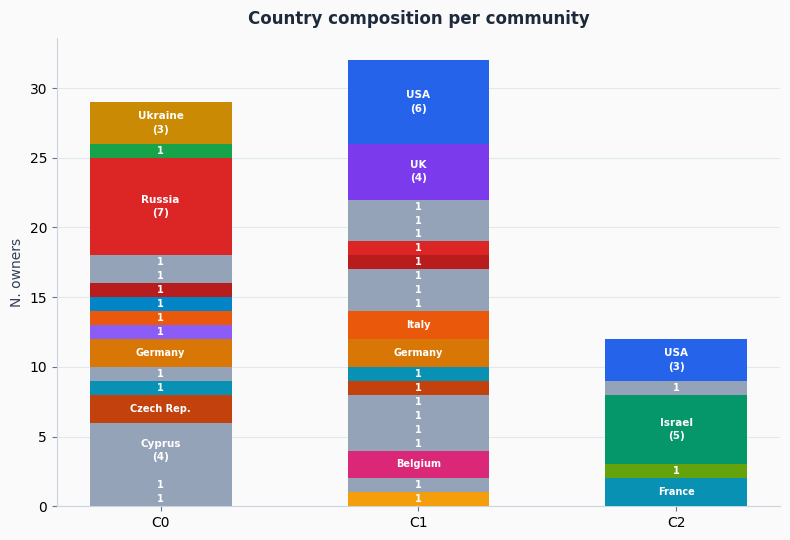

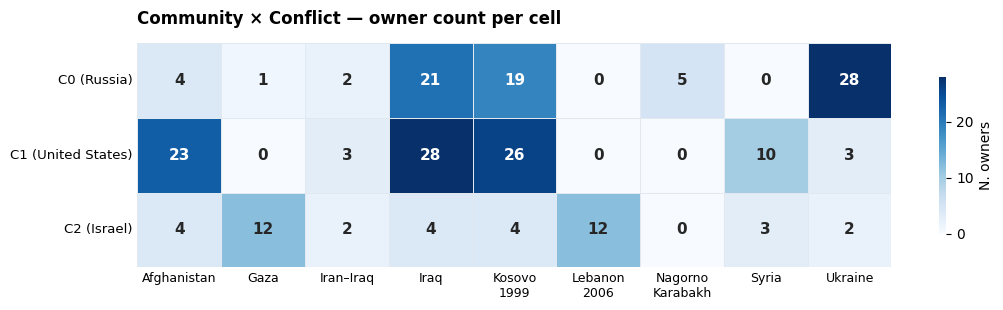

Saved: figures/community_country_composition.png, community_conflict_heatmap.png


In [5]:
# community detection (Louvain) 
from IPython.display import display

partition = community_louvain.best_partition(G_owner, weight='weight', random_state=42)
centrality_df['community'] = centrality_df['owner'].map(partition)
centrality_df.to_csv('owner_centrality.csv', index=False)

comm_ids      = sorted(set(partition.values()))
n_communities = len(comm_ids)
print(f'Communities found: {n_communities}')

# ── palette paese (condivisa con Cell 8)
COUNTRY_COLORS = {
    'United States':                    '#2563eb',
    'Russia':                           '#dc2626',
    'United Kingdom':                   '#7c3aed',
    'France':                           '#0891b2',
    'Germany':                          '#d97706',
    'Israel':                           '#059669',
    'Italy':                            '#ea580c',
    'Belgium':                          '#db2777',
    "People's Republic of China":       '#b91c1c',
    'Iran':                             '#65a30d',
    'Ukraine':                          '#ca8a04',
    'India':                            '#8b5cf6',
    'Argentina':                        '#f59e0b',
    'Jersey':                           '#0284c7',
    'Czech Republic':                   '#c2410c',
    'Turkey':                           '#16a34a',
}
SHORT_NAMES = {
    'United States':                    'USA',
    'Russia':                           'Russia',
    'United Kingdom':                   'UK',
    'France':                           'France',
    'Germany':                          'Germany',
    'Israel':                           'Israel',
    'Italy':                            'Italy',
    'Belgium':                          'Belgium',
    "People's Republic of China":       'China',
    'Iran':                             'Iran',
    'Ukraine':                          'Ukraine',
    'India':                            'India',
    'Argentina':                        'Argentina',
    'Jersey':                           'Jersey',
    'Czech Republic':                   'Czech Rep.',
    'Turkey':                           'Turkey',
}
DEFAULT_COLOR = '#94a3b8'

_conflict_labels = {
    'afghanistan':      'Afghanistan',
    'gaza':             'Gaza',
    'iran_iraq':        'Iran–Iraq',
    'iraq':             'Iraq',
    'kosovo_1999':      'Kosovo\n1999',
    'lebanon_2006':     'Lebanon\n2006',
    'nagorno_karabakh': 'Nagorno\nKarabakh',
    'syria':            'Syria',
    'ukraine':          'Ukraine',
}

TABLE_STYLES = [
    {'selector': 'th',      'props': [('background-color', '#1e293b'), ('color', 'white'),
                                       ('font-size', '11px'), ('padding', '8px 12px'),
                                       ('text-align', 'left'), ('font-weight', 'bold')]},
    {'selector': 'td',      'props': [('font-size', '11px'), ('padding', '6px 12px'),
                                       ('border-bottom', '1px solid #e2e8f0')]},
    {'selector': 'table',   'props': [('border-collapse', 'collapse'), ('margin', '12px 0')]},
    {'selector': 'tr:hover td', 'props': [('background-color', '#f1f5f9')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '12px'),
                                       ('font-weight', 'bold'), ('color', '#1e293b'),
                                       ('padding', '8px 0'), ('text-align', 'left')]},
]


def comm_info(comm_id):
    members   = [n for n, c in partition.items() if c == comm_id]
    sub       = centrality_df[centrality_df['owner'].isin(members)]
    countries = sub['country'].value_counts()
    dominant  = countries.index[0] if len(countries) > 0 else 'unknown'
    return members, sub, dominant

# Summary table
rows = []
for cid in comm_ids:
    members, sub, dominant = comm_info(cid)
    n_systemic = int((sub['n_conflicts'] >= 4).sum())
    top_owners = ', '.join(sub.nlargest(3, 'n_conflicts')['owner'].tolist())
    rows.append({
        'community':  f'C{cid}',
        'dominant':   dominant,
        'n_members':  len(members),
        'n_systemic': n_systemic,
        'top owners': top_owners,
    })

display(
    pd.DataFrame(rows).style
    .background_gradient(subset=['n_members'],  cmap='Blues')
    .background_gradient(subset=['n_systemic'], cmap='YlOrRd')
    .set_caption('Community summary — Louvain on owner-owner projection')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)

# Community composition
comm_country = {}
for cid in comm_ids:
    members, sub, _ = comm_info(cid)
    comm_country[cid] = sub['country'].value_counts()

all_countries = sorted({c for v in comm_country.values() for c in v.index})

fig, ax = plt.subplots(figsize=(8, 5.5))
fig.patch.set_facecolor('#fafafa')
ax.set_facecolor('#fafafa')

bottom = np.zeros(len(comm_ids))
for country in all_countries:
    vals  = np.array([comm_country[cid].get(country, 0) for cid in comm_ids])
    color = COUNTRY_COLORS.get(country, DEFAULT_COLOR)
    ax.bar([f'C{c}' for c in comm_ids], vals, bottom=bottom,
           color=color, width=0.55, zorder=3)
    short = SHORT_NAMES.get(country, country)
    for i, v in enumerate(vals):
        if v >= 3:
            # nome + conteggio su due righe
            ax.text(i, bottom[i] + v / 2, f'{short}\n({v})',
                    ha='center', va='center', fontsize=7.5,
                    color='white', fontweight='bold', linespacing=1.4)
        elif v == 2:
            # solo nome abbreviato
            ax.text(i, bottom[i] + v / 2, short,
                    ha='center', va='center', fontsize=7,
                    color='white', fontweight='bold')
        elif v == 1:
            # solo numero
            ax.text(i, bottom[i] + v / 2, '1',
                    ha='center', va='center', fontsize=7,
                    color='white', fontweight='bold')
    bottom += vals

ax.set_ylabel('N. owners', fontsize=10, color='#334155')
ax.set_title('Country composition per community',
             fontsize=12, fontweight='bold', color='#1e293b', pad=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cbd5e1')
ax.spines['bottom'].set_color('#cbd5e1')
ax.yaxis.grid(True, color='#e2e8f0', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(labelsize=10, color='#64748b')

plt.tight_layout()
plt.savefig('figures/community_country_composition.png', dpi=150,
            bbox_inches='tight', facecolor='#fafafa')
plt.show()

# heatmap
ccm_rows = []
for cid in comm_ids:
    members, _, dominant = comm_info(cid)
    row = {'community': f'C{cid} ({dominant})'}
    for conf in conflicts:
        row[_conflict_labels.get(conf, conf)] = sum(1 for m in members if B.has_edge(m, conf))
    ccm_rows.append(row)

ccm_df = pd.DataFrame(ccm_rows).set_index('community')

fig, ax = plt.subplots(figsize=(11, 3.2))
fig.patch.set_facecolor('white')

sns.heatmap(
    ccm_df, ax=ax,
    cmap=sns.color_palette('Blues', as_cmap=True),
    linewidths=0.6, linecolor='#e2e8f0',
    annot=True, fmt='d', annot_kws={'size': 11, 'weight': 'bold'},
    cbar_kws={'label': 'N. owners', 'shrink': 0.7},
)

ax.set_title('Community × Conflict — owner count per cell',
             fontsize=12, fontweight='bold', pad=14, loc='left')
ax.set_xlabel('', fontsize=0)
ax.set_ylabel('', fontsize=0)
ax.tick_params(axis='y', labelsize=9.5, length=0, rotation=0)
ax.tick_params(axis='x', labelsize=9,   length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig('figures/community_conflict_heatmap.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: figures/community_country_composition.png, community_conflict_heatmap.png')

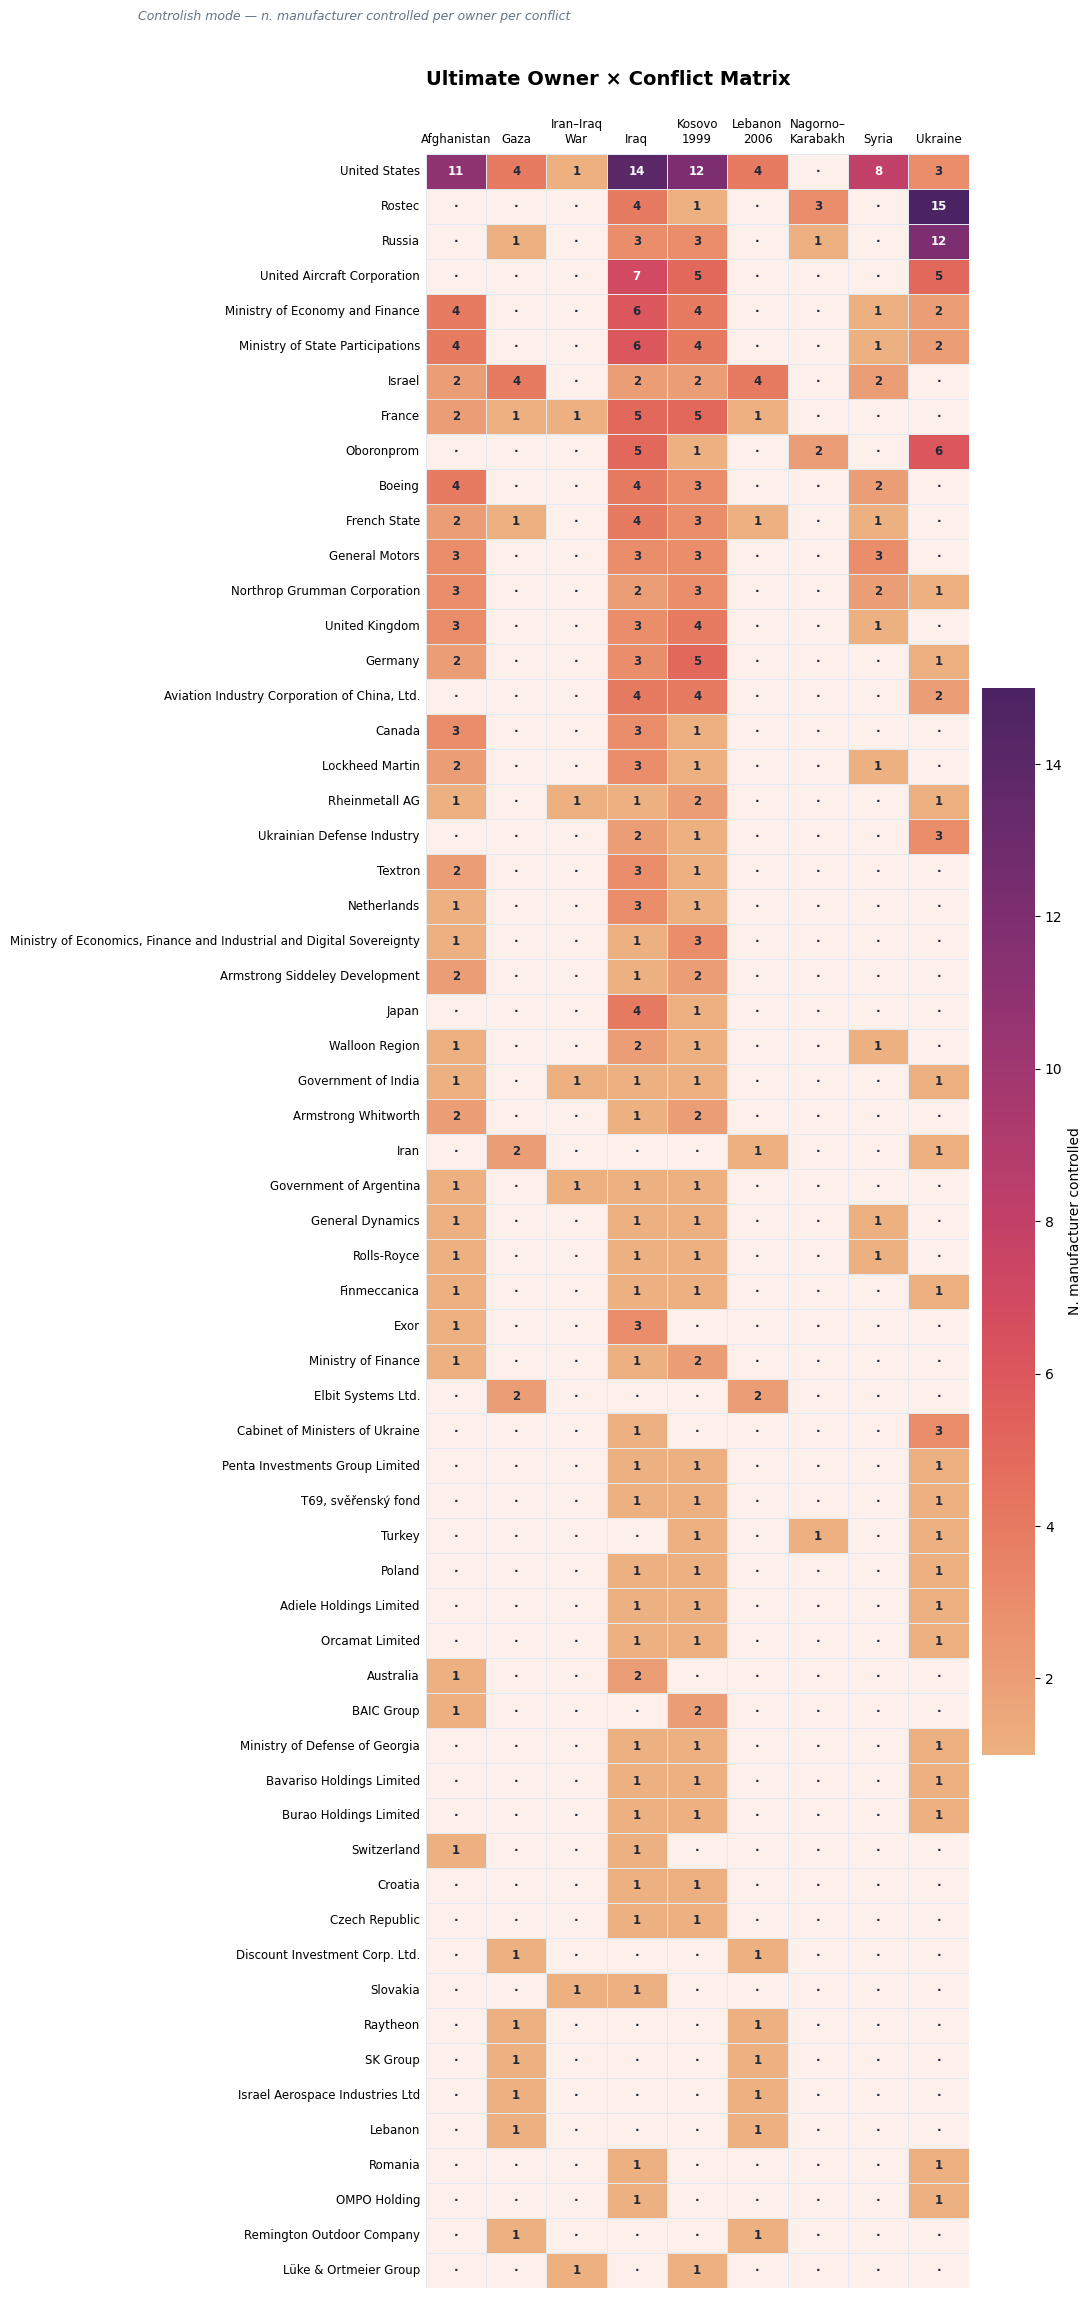

Saved: figures/heatmap_owner_conflict.png


In [6]:
# heatmap owner × conflitto

cross = pd.read_csv('ultimate_owners_cross_conflict.csv')
relevant_owners = cross[cross['n_conflitti'] >= 2]['ultimateOwnerLabel'].tolist()

heatmap_data = matrix_df[matrix_df.index.isin(relevant_owners)].copy()
heatmap_data['total'] = heatmap_data.sum(axis=1)
heatmap_data = heatmap_data.sort_values('total', ascending=False).drop(columns='total')

col_rename = {
    'afghanistan':      'Afghanistan',
    'gaza':             'Gaza',
    'iran_iraq':        'Iran–Iraq\nWar',
    'iraq':             'Iraq',
    'kosovo_1999':      'Kosovo\n1999',
    'lebanon_2006':     'Lebanon\n2006',
    'nagorno_karabakh': 'Nagorno–\nKarabakh',
    'syria':            'Syria',
    'ukraine':          'Ukraine',
}
heatmap_data = heatmap_data.rename(columns=col_rename)

max_val = heatmap_data.values.max()

cmap = sns.color_palette('flare', as_cmap=True).copy()
cmap.set_under('#fdf0ea')  # quasi-bianco caldo, molto più chiaro del valore 1

fig, ax = plt.subplots(figsize=(11, max(9, len(heatmap_data) * 0.38)))

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap=cmap,
    linewidths=0.6,
    linecolor='#e2e8f0',
    annot=False,
    cbar_kws={'label': 'N. manufacturer controlled', 'shrink': 0.5, 'pad': 0.02},
    vmin=1,
    vmax=max_val,
)

THRESHOLD = max_val * 0.45
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        v = heatmap_data.iloc[i, j]
        text_color = '#f8fafc' if v >= THRESHOLD else '#1e293b'
        label = str(int(v)) if v > 0 else '·'
        ax.text(j + 0.5, i + 0.5, label, ha='center', va='center',
                fontsize=8.5, fontweight='bold', color=text_color, zorder=3)

ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

ax.set_title('Ultimate Owner × Conflict Matrix',
             fontsize=14, fontweight='bold', pad=24, loc='left')
fig.text(0.13, 0.985,
         'Controlish mode — n. manufacturer controlled per owner per conflict',
         ha='left', fontsize=9, color='#64748b', style='italic',
         transform=fig.transFigure)

ax.set_xlabel('', fontsize=0)
ax.set_ylabel('', fontsize=0)
ax.tick_params(axis='y', labelsize=8.5, length=0, pad=4)
ax.tick_params(axis='x', labelsize=8.5, length=0, pad=6)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('figures/heatmap_owner_conflict.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: figures/heatmap_owner_conflict.png')

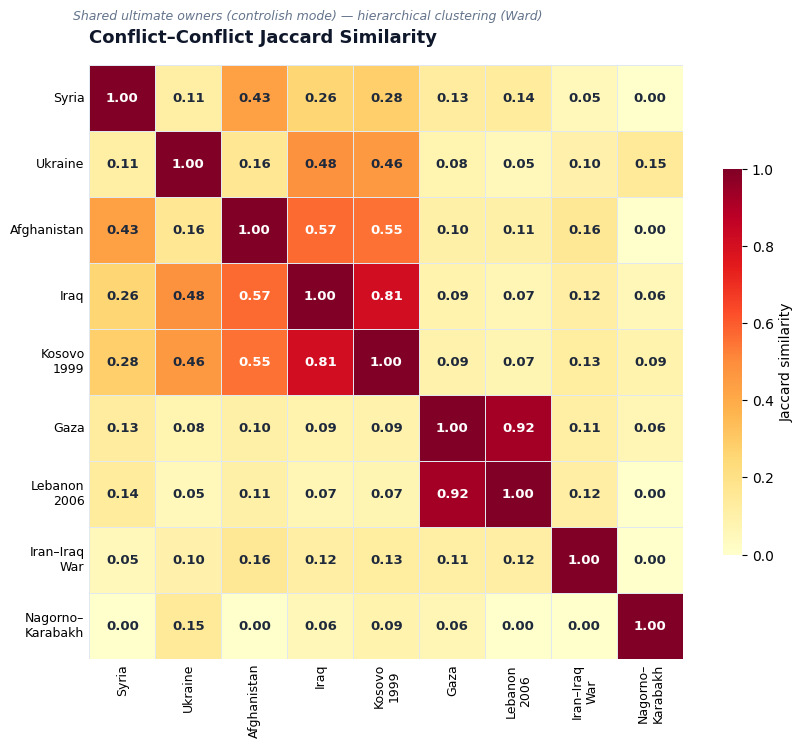

Saved: figures/conflict_jaccard_similarity.png

Top conflicts couples per Jaccard similarity:
  gaza                 — lebanon_2006          Jaccard = 0.923
  iraq                 — kosovo_1999           Jaccard = 0.811
  afghanistan          — iraq                  Jaccard = 0.569
  afghanistan          — kosovo_1999           Jaccard = 0.551
  iraq                 — ukraine               Jaccard = 0.481
  kosovo_1999          — ukraine               Jaccard = 0.460

Less similar couples:
  iran_iraq            — nagorno_karabakh      Jaccard = 0.000
  lebanon_2006         — nagorno_karabakh      Jaccard = 0.000
  nagorno_karabakh     — syria                 Jaccard = 0.000


In [7]:
# Jaccard similarity tra conflitti 

from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, leaves_list

bin_mat = (matrix_df > 0).astype(int)   # shape: n_owners × n_conflicts

conflict_cols = list(bin_mat.columns)
n = len(conflict_cols)

jac = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        a = bin_mat.iloc[:, i].values
        b = bin_mat.iloc[:, j].values
        inter = int((a & b).sum())
        union = int((a | b).sum())
        jac[i, j] = inter / union if union > 0 else 0.0

jac_df = pd.DataFrame(jac, index=conflict_cols, columns=conflict_cols)
jac_df.to_csv('conflict_jaccard_similarity.csv')

dist_condensed = squareform(np.clip(1 - jac_df.values, 0, None))
link           = linkage(dist_condensed, method='ward')
order          = leaves_list(link)

jac_ord = jac_df.iloc[order, :].iloc[:, order]

pretty = {c: col_rename.get(c, c).replace('\n', '\n') for c in conflict_cols}
jac_ord_plot = jac_ord.rename(index=pretty, columns=pretty)

# heatmap
fig, ax = plt.subplots(figsize=(9, 7.5))
fig.patch.set_facecolor('white')

cmap_j = sns.color_palette('YlOrRd', as_cmap=True)

sns.heatmap(
    jac_ord_plot,
    ax=ax,
    cmap=cmap_j,
    vmin=0, vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 9.5, 'weight': 'bold'},
    linewidths=0.6, linecolor='#e2e8f0',
    cbar_kws={'label': 'Jaccard similarity', 'shrink': 0.65},
    square=True,
)

for i in range(jac_ord_plot.shape[0]):
    for j in range(jac_ord_plot.shape[1]):
        v = jac_ord_plot.iloc[i, j]
        ax.texts[i * n + j].set_color('white' if v > 0.55 else '#1e293b')

ax.set_title('Conflict–Conflict Jaccard Similarity',
             fontsize=13, fontweight='bold', pad=16, loc='left', color='#0f172a')
fig.text(0.13, 0.965,
         'Shared ultimate owners (controlish mode) — hierarchical clustering (Ward)',
         ha='left', fontsize=9, color='#64748b', style='italic',
         transform=fig.transFigure)

ax.tick_params(axis='both', length=0, labelsize=9)
ax.set_xlabel(''); ax.set_ylabel('')
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('figures/conflict_jaccard_similarity.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: figures/conflict_jaccard_similarity.png')

print('\nTop conflicts couples per Jaccard similarity:')
pairs = []
for i in range(n):
    for j in range(i+1, n):
        pairs.append((conflict_cols[i], conflict_cols[j], round(jac[i, j], 3)))
pairs.sort(key=lambda x: -x[2])
for c1, c2, v in pairs[:6]:
    print(f'  {c1:<20} — {c2:<20}  Jaccard = {v:.3f}')
print('\nLess similar couples:')
for c1, c2, v in pairs[-3:]:
    print(f'  {c1:<20} — {c2:<20}  Jaccard = {v:.3f}')

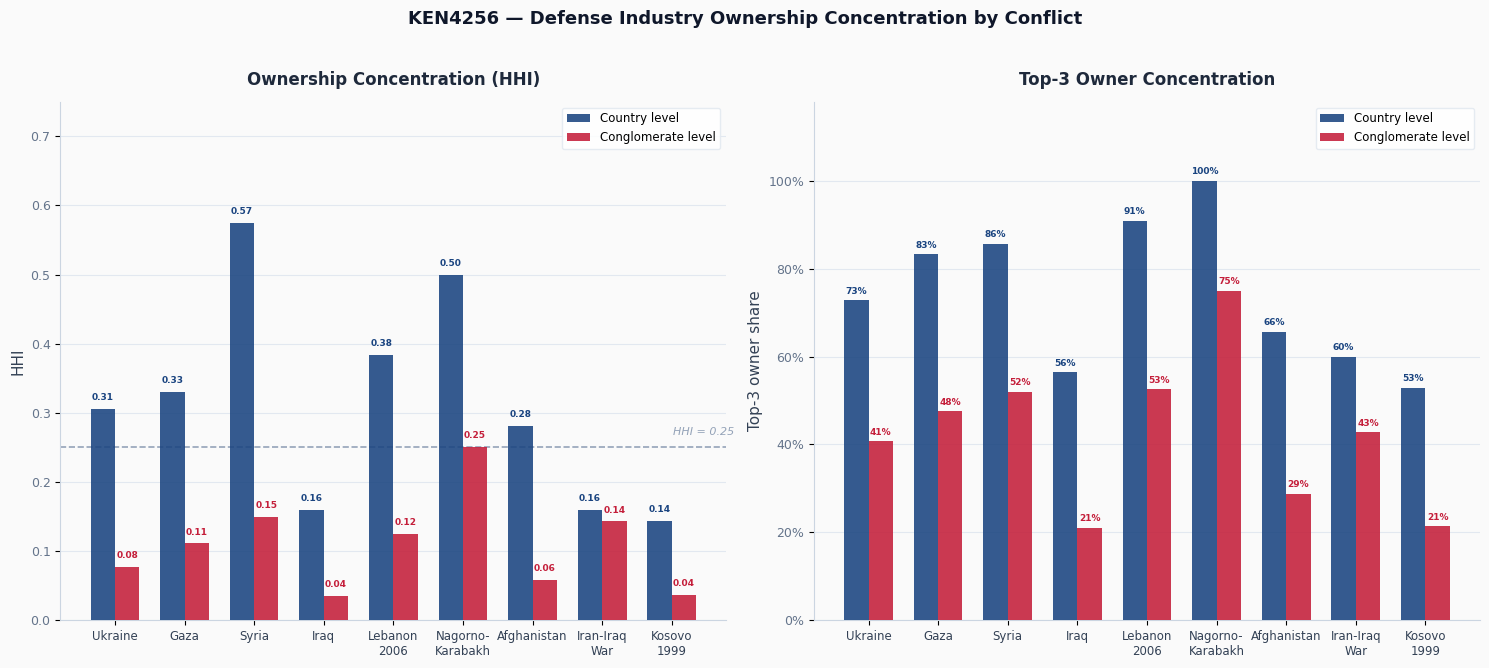

Saved: figures/hhi_per_conflict.png


In [8]:
# bar chart HHI comparativo 

hhi_all = pd.read_csv('hhi_per_conflict.csv')

conflict_order = ['ukraine','gaza','syria','iraq','lebanon_2006',
                  'nagorno_karabakh','afghanistan','iran_iraq','kosovo_1999']
conflict_labels = {
    'ukraine':          'Ukraine',
    'gaza':             'Gaza',
    'syria':            'Syria',
    'iraq':             'Iraq',
    'lebanon_2006':     'Lebanon\n2006',
    'nagorno_karabakh': 'Nagorno-\nKarabakh',
    'afghanistan':      'Afghanistan',
    'iran_iraq':        'Iran-Iraq\nWar',
    'kosovo_1999':      'Kosovo\n1999',
}

hhi_al_plot   = hhi_all[hhi_all['mode'].str.contains('all_links')].copy()
hhi_ctrl_plot = hhi_all[hhi_all['mode'].str.contains('controlish')].copy()

hhi_al_plot['order']   = hhi_al_plot['conflict'].map({c: i for i, c in enumerate(conflict_order)})
hhi_ctrl_plot['order'] = hhi_ctrl_plot['conflict'].map({c: i for i, c in enumerate(conflict_order)})
hhi_al_plot   = hhi_al_plot.sort_values('order')
hhi_ctrl_plot = hhi_ctrl_plot.sort_values('order')

x      = np.arange(len(conflict_order))
width  = 0.35
labels = [conflict_labels.get(c, c) for c in conflict_order]

COLOR_AL   = '#1a4480'   
COLOR_CTRL = '#c41e3a'   

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
fig.patch.set_facecolor('#fafafa')

for ax in axes:
    ax.set_facecolor('#fafafa')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#cbd5e1')
    ax.spines['bottom'].set_color('#cbd5e1')
    ax.yaxis.grid(True, color='#e2e8f0', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

ax1 = axes[0]
b1 = ax1.bar(x - width/2, hhi_al_plot['hhi'],  width,
             label='Country level',      color=COLOR_AL,   alpha=0.88, zorder=3)
b2 = ax1.bar(x + width/2, hhi_ctrl_plot['hhi'], width,
             label='Conglomerate level', color=COLOR_CTRL, alpha=0.88, zorder=3)

for bar in b1:
    v = bar.get_height()
    if v > 0.025:
        ax1.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.2f}',
                 ha='center', va='bottom', fontsize=6.5,
                 color=COLOR_AL, fontweight='bold')
for bar in b2:
    v = bar.get_height()
    if v > 0.025:
        ax1.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.2f}',
                 ha='center', va='bottom', fontsize=6.5,
                 color=COLOR_CTRL, fontweight='bold')

ax1.axhline(0.25, color='#94a3b8', linestyle='--', linewidth=1.2, zorder=2)
ax1.text(len(conflict_order) - 0.1, 0.265, 'HHI = 0.25',
         ha='right', va='bottom', fontsize=8, color='#94a3b8', style='italic')

ax1.set_ylabel('HHI', fontsize=11, color='#334155')
ax1.set_title('Ownership Concentration (HHI)',
              fontsize=12, fontweight='bold', color='#1e293b', pad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=0, ha='center', fontsize=8.5, color='#334155')
ax1.legend(fontsize=8.5, framealpha=0.85, edgecolor='#e2e8f0', loc='upper right')
ax1.set_ylim(0, 0.75)
ax1.tick_params(axis='y', labelcolor='#64748b', labelsize=9)

ax2 = axes[1]
b3 = ax2.bar(x - width/2, hhi_al_plot['top3_share'],  width,
             label='Country level',      color=COLOR_AL,   alpha=0.88, zorder=3)
b4 = ax2.bar(x + width/2, hhi_ctrl_plot['top3_share'], width,
             label='Conglomerate level', color=COLOR_CTRL, alpha=0.88, zorder=3)

for bar in b3:
    v = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.0%}',
             ha='center', va='bottom', fontsize=6.5,
             color=COLOR_AL, fontweight='bold')
for bar in b4:
    v = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f'{v:.0%}',
             ha='center', va='bottom', fontsize=6.5,
             color=COLOR_CTRL, fontweight='bold')

ax2.set_ylabel('Top-3 owner share', fontsize=11, color='#334155')
ax2.set_title('Top-3 Owner Concentration',
              fontsize=12, fontweight='bold', color='#1e293b', pad=12)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=0, ha='center', fontsize=8.5, color='#334155')
ax2.legend(fontsize=8.5, framealpha=0.85, edgecolor='#e2e8f0', loc='upper right')
ax2.set_ylim(0, 1.18)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax2.tick_params(axis='y', labelcolor='#64748b', labelsize=9)

fig.suptitle('KEN4256 — Defense Industry Ownership Concentration by Conflict',
             fontsize=13, fontweight='bold', color='#0f172a', y=1.02)
plt.tight_layout()
plt.savefig('figures/hhi_per_conflict.png', dpi=150, bbox_inches='tight',
            facecolor='#fafafa')
plt.show()
print('Saved: figures/hhi_per_conflict.png')

Owner nel grafo (>= 2 conflitti): 62


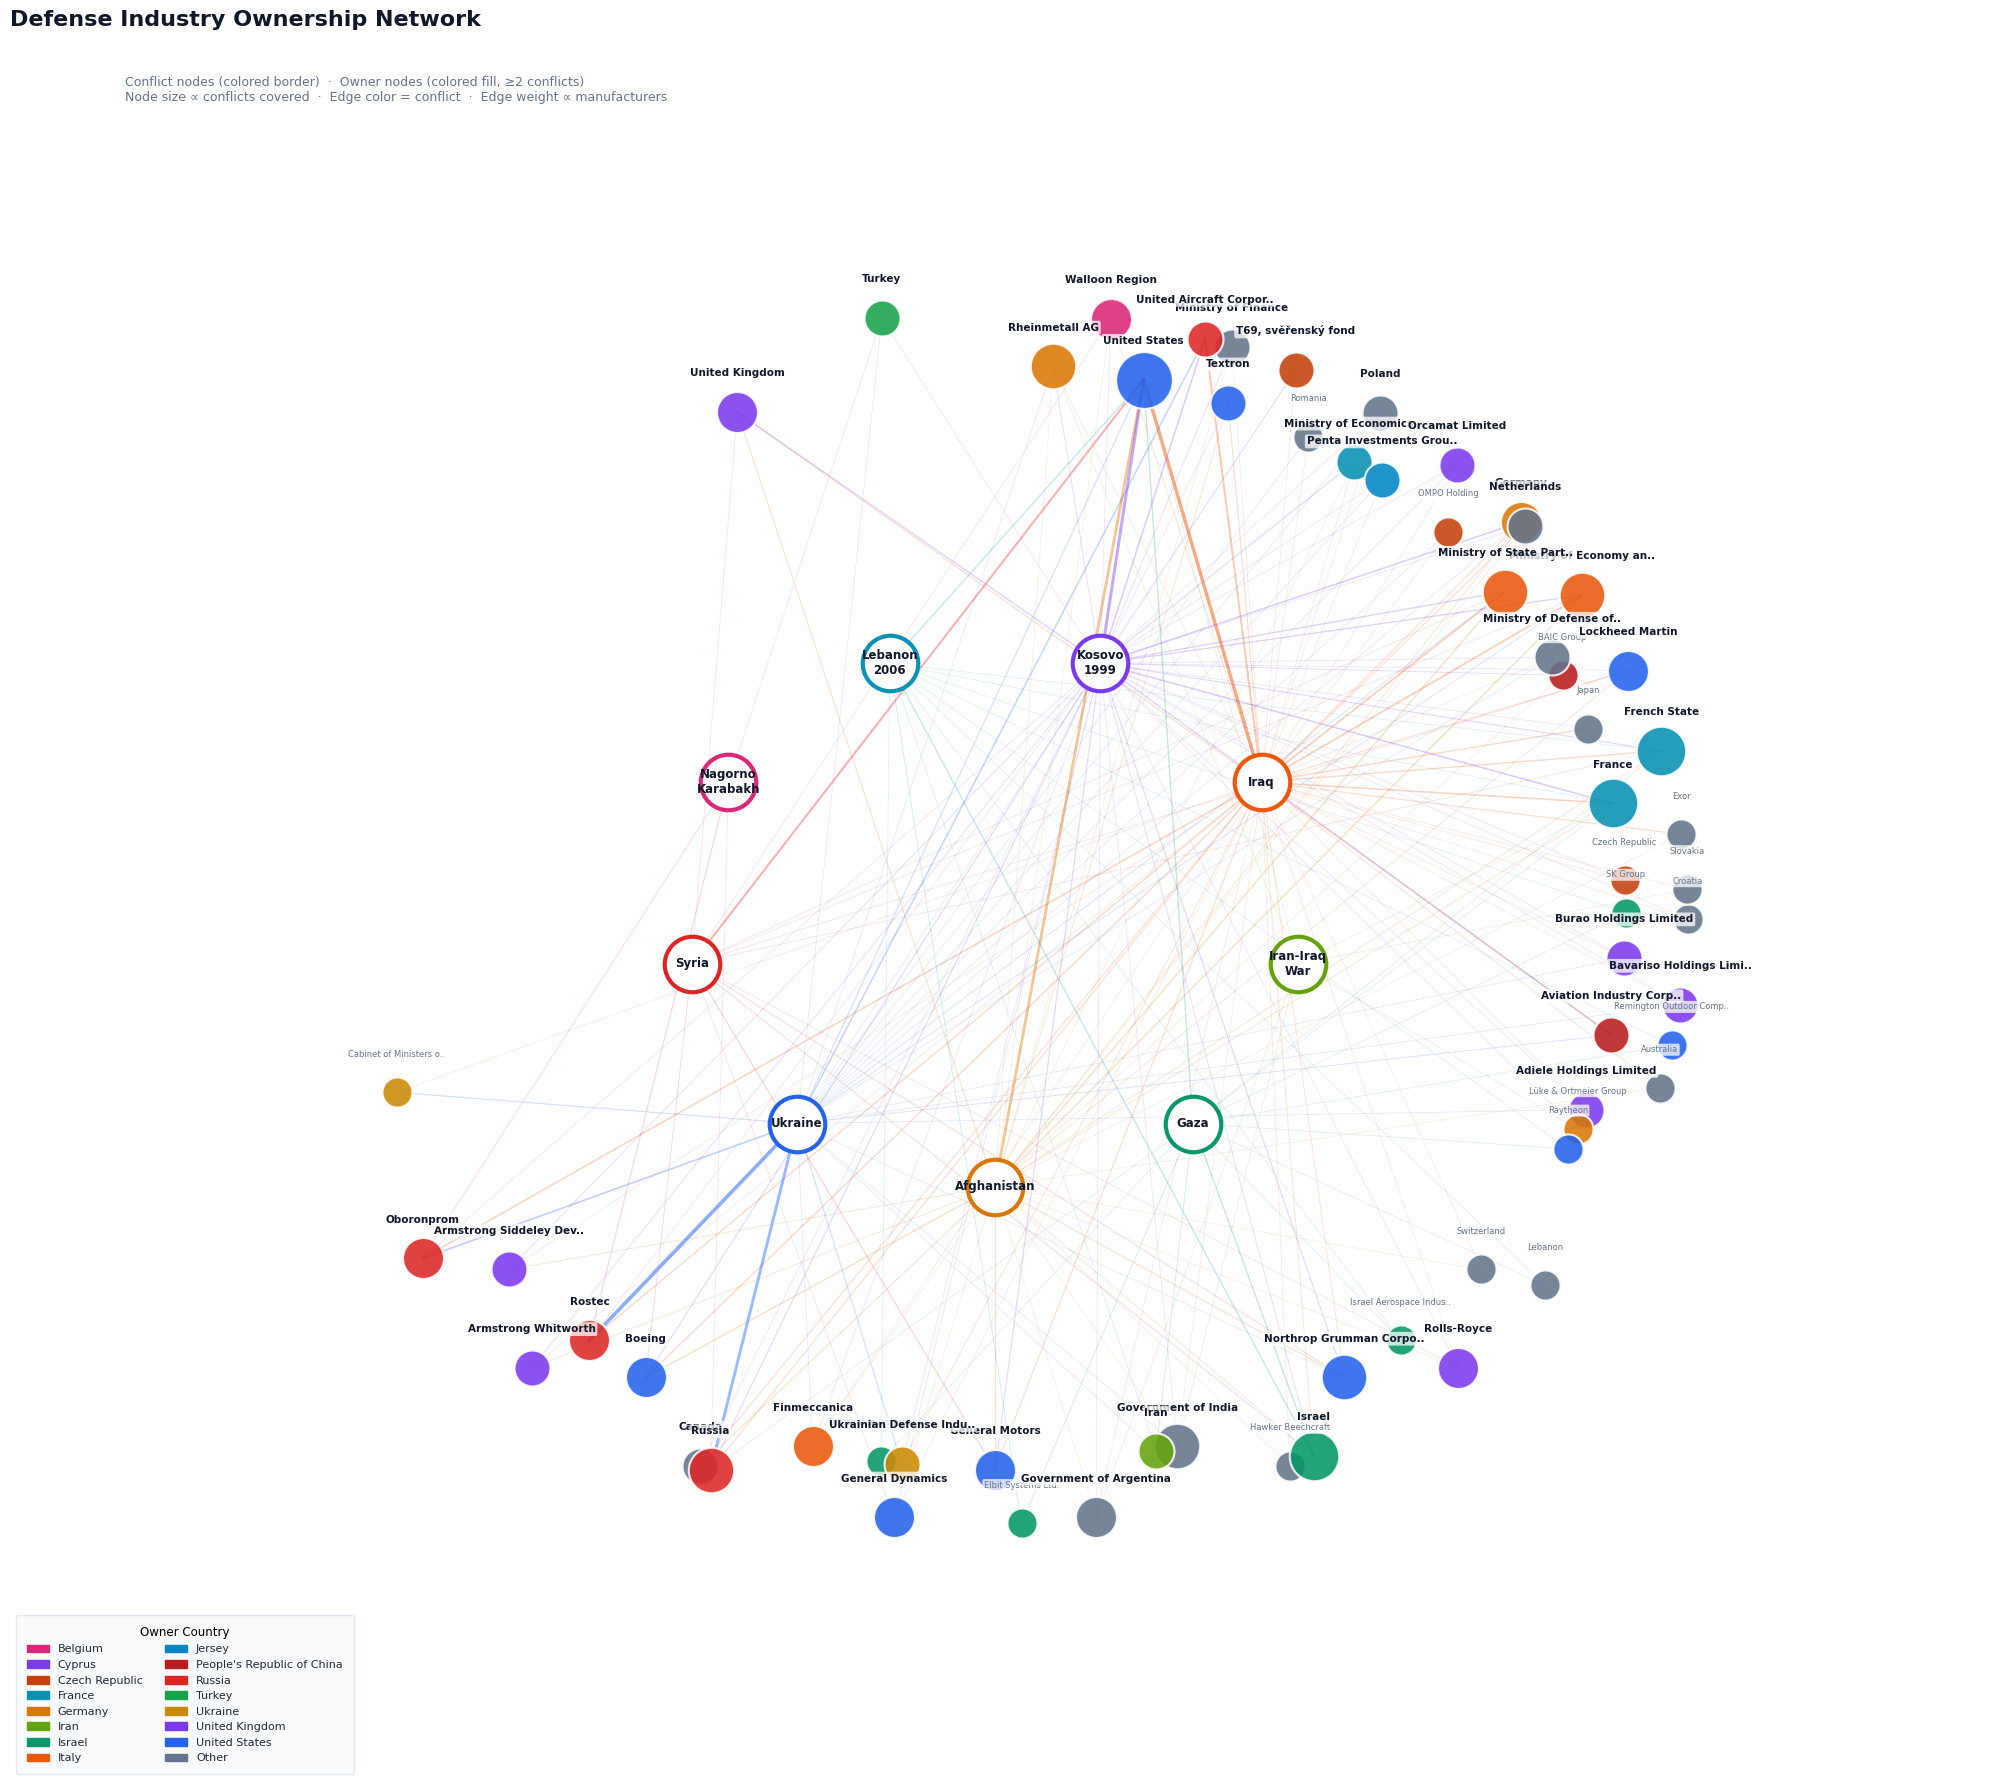

Saved: figures/network_owner_conflict.png


In [9]:
# Visualization of Bipartite Graph

owners_filtered = [o for o in owners if len([c for c in conflicts if B.has_edge(o, c)]) >= 2]
B_sub = B.subgraph(conflicts + owners_filtered).copy()
print(f'Owner nel grafo (>= 2 conflitti): {len(owners_filtered)}')

pos_vis = {}
n_conf  = len(conflicts)
for i, c in enumerate(sorted(conflicts)):
    angle = 2 * np.pi * i / n_conf - np.pi / 2
    pos_vis[c] = (0.40 * np.cos(angle), 0.40 * np.sin(angle))

owner_main_conflict = {}
for o in owners_filtered:
    weights = {c: B[o][c]['weight'] for c in conflicts if B.has_edge(o, c)}
    owner_main_conflict[o] = max(weights, key=weights.get)

conflict_owners = defaultdict(list)
for o, c in owner_main_conflict.items():
    conflict_owners[c].append(o)

for conf_i, c in enumerate(sorted(conflicts)):
    center_angle = 2 * np.pi * conf_i / n_conf - np.pi / 2
    members = conflict_owners[c]
    spread  = min(np.pi * 0.28, np.pi * 0.28 * len(members) / 8)
    for j, o in enumerate(members):
        a = center_angle if len(members) == 1 else \
            center_angle - spread + 2 * spread * j / (len(members) - 1)
        r = 0.82 + 0.08 * (j % 2)
        pos_vis[o] = (r * np.cos(a), r * np.sin(a))

# ── palette paese (owner)
country_colors = {
    'United States':                    '#2563eb',
    'Russia':                           '#dc2626',
    'United Kingdom':                   '#7c3aed',
    'France':                           '#0891b2',
    'Germany':                          '#d97706',
    'Israel':                           '#059669',
    'Italy':                            '#ea580c',
    'Belgium':                          '#db2777',
    "People's Republic of China":       '#b91c1c',
    'Iran':                             '#65a30d',
    'Ukraine':                          '#ca8a04',
    'Cyprus':                           '#7c3aed',
    'Czech Republic':                   '#c2410c',
    'Denmark':                          '#a21caf',
    'Turkey':                           '#16a34a',
    'Jersey':                           '#0284c7',
}
DEFAULT_COLOR = '#64748b'

conflict_hue = {
    'afghanistan':      '#d97706',
    'gaza':             '#059669',
    'iran_iraq':        '#65a30d',
    'iraq':             '#ea580c',
    'kosovo_1999':      '#7c3aed',
    'lebanon_2006':     '#0891b2',
    'nagorno_karabakh': '#db2777',
    'syria':            '#dc2626',
    'ukraine':          '#2563eb',
}

def owner_color(o):
    m = ult[ult['ultimateOwnerLabel'] == o]
    c = m['ultimateOwnerCountry'].iloc[0] if len(m) > 0 else ''
    return country_colors.get(str(c), DEFAULT_COLOR)

fig, ax = plt.subplots(figsize=(20, 18))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

max_w = max((B_sub[u][v].get('weight', 1) for u, v in B_sub.edges()), default=1)
for u, v, data in B_sub.edges(data=True):
    if u not in pos_vis or v not in pos_vis:
        continue
    conflict_node = v if v in conflicts else u
    w     = data.get('weight', 1)
    alpha = 0.12 + 0.40 * (w / max_w)
    lw    = 0.4  + 2.2  * (w / max_w)
    xu, yu = pos_vis[u]
    xv, yv = pos_vis[v]
    color = conflict_hue.get(conflict_node, '#94a3b8')
    ax.plot([xu, xv], [yu, yv], color=color, alpha=alpha, linewidth=lw, zorder=1)

for o in owners_filtered:
    if o not in pos_vis:
        continue
    xo, yo = pos_vis[o]
    nc     = len([c for c in conflicts if B.has_edge(o, c)])
    size   = 70 + nc * 200
    color  = owner_color(o)
    ax.scatter(xo, yo, s=size, color=color, zorder=3, alpha=0.88,
               edgecolors='white', linewidths=1.5)
    short = o[:22] + '..' if len(o) > 24 else o
    fs    = 7.5 if nc >= 3 else 6.0
    col   = '#0f172a' if nc >= 3 else '#64748b'
    ax.text(xo, yo + 0.050, short, ha='center', va='bottom', fontsize=fs,
            color=col, zorder=5, fontweight='bold' if nc >= 3 else 'normal',
            bbox=dict(boxstyle='round,pad=0.18', facecolor='white',
                      alpha=0.75, linewidth=0))

conflict_labels_map = {
    'afghanistan':      'Afghanistan',
    'gaza':             'Gaza',
    'iran_iraq':        'Iran-Iraq\nWar',
    'iraq':             'Iraq',
    'kosovo_1999':      'Kosovo\n1999',
    'lebanon_2006':     'Lebanon\n2006',
    'nagorno_karabakh': 'Nagorno\nKarabakh',
    'syria':            'Syria',
    'ukraine':          'Ukraine',
}
for c in conflicts:
    if c not in pos_vis:
        continue
    xc, yc = pos_vis[c]
    ccolor = conflict_hue.get(c, '#334155')
    ax.scatter(xc, yc, s=1600, color='white', zorder=4,
               edgecolors=ccolor, linewidths=3.0)
    ax.text(xc, yc, conflict_labels_map.get(c, c), ha='center', va='center',
            fontsize=8.5, fontweight='bold', color='#0f172a', zorder=5)


patches = [mpatches.Patch(color=col, label=ctr)
           for ctr, col in sorted(country_colors.items())
           if any(owner_color(o) == col for o in owners_filtered)]
patches.append(mpatches.Patch(color=DEFAULT_COLOR, label='Other'))
ax.legend(handles=patches, loc='lower left', fontsize=8,
          facecolor='#f8fafc', edgecolor='#e2e8f0', labelcolor='#1e293b',
          title='Owner Country', title_fontsize=8.5, ncol=2,
          framealpha=0.95, borderpad=1.0)

ax.set_title('Defense Industry Ownership Network',
             color='#0f172a', fontsize=16, fontweight='bold', pad=20, loc='left')
fig.text(0.065, 0.955,
         'Conflict nodes (colored border)  ·  Owner nodes (colored fill, ≥2 conflicts)\n'
         'Node size ∝ conflicts covered  ·  Edge color = conflict  ·  Edge weight ∝ manufacturers',
         color='#64748b', fontsize=9, va='top', transform=fig.transFigure)

ax.set_xlim(-1.28, 1.28)
ax.set_ylim(-1.28, 1.28)
ax.axis('off')

plt.tight_layout()
plt.savefig('figures/network_owner_conflict.png', dpi=180, bbox_inches='tight',
            facecolor='white')
plt.show()
print('Saved: figures/network_owner_conflict.png')

In [10]:
# Results Recap
from IPython.display import display

print('=' * 60)
print('RECAP MAIN RESULTS')
print('=' * 60)

print(f'\nDataset: {ult["conflict"].str.split("|").explode().nunique()} conflicts, '
      f'{ult["manufacturer"].nunique()} manufacturer, '
      f'{ult["ultimateOwner"].nunique()} ultimate owners')

print('\n── Systemic players (owner in >= 4 conflicts, controlish):')
systemic = centrality_df[centrality_df['n_conflicts'] >= 4][['owner','country','n_conflicts','degree_w']]

TABLE_STYLES = [
    {'selector': 'th',      'props': [('background-color', '#1e293b'), ('color', 'white'),
                                       ('font-size', '11px'), ('padding', '8px 12px'),
                                       ('text-align', 'left'), ('font-weight', 'bold')]},
    {'selector': 'td',      'props': [('font-size', '11px'), ('padding', '6px 12px'),
                                       ('border-bottom', '1px solid #e2e8f0')]},
    {'selector': 'table',   'props': [('border-collapse', 'collapse'), ('margin', '12px 0')]},
    {'selector': 'tr:hover td', 'props': [('background-color', '#f1f5f9')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '12px'),
                                       ('font-weight', 'bold'), ('color', '#1e293b'),
                                       ('padding', '8px 0'), ('text-align', 'left')]},
]

display(
    systemic.style
    .background_gradient(subset=['n_conflicts'], cmap='Blues')
    .background_gradient(subset=['degree_w'], cmap='Greens')
    .set_caption('Systemic players — owners in ≥4 conflicts (controlish mode)')
    .set_table_styles(TABLE_STYLES)
    .hide(axis='index')
)



RECAP MAIN RESULTS

Dataset: 9 conflicts, 194 manufacturer, 145 ultimate owners

── Systemic players (owner in >= 4 conflicts, controlish):


owner,country,n_conflicts,degree_w
United States,United States,8,57
French State,France,6,12
Israel,Israel,6,16
France,France,6,15
Northrop Grumman Corporation,United States,5,11
Ministry of Economy and Finance,Italy,5,17
Government of India,India,5,5
Ministry of State Participations,Italy,5,17
Rheinmetall AG,Germany,5,6
Russia,Russia,5,20
